# Rainfall Analysis and Prediction using IMD Sub-Division Data

**Dataset:** *Sub Divisional Monthly Rainfall from 1901 to 2017*, published by the India Meteorological Department (Ministry of Earth Sciences).
Link: https://data.gov.in/resource/sub-divisional-monthly-rainfall-1901-2017

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
warnings.filterwarnings("ignore")

from sklearn.linear_model import LinearRegression, LogisticRegression
from sklearn.preprocessing import PolynomialFeatures, StandardScaler
from sklearn.neighbors import KNeighborsClassifier
from sklearn.naive_bayes import GaussianNB
from sklearn.tree import DecisionTreeClassifier
from sklearn.svm import SVC
from sklearn.metrics import (r2_score, mean_absolute_error, mean_squared_error,
                             accuracy_score, precision_score, recall_score, f1_score, confusion_matrix)

## Loading the dataset

In [2]:
df = pd.read_csv("Sub_Division_IMD_2017.csv")
df.head()

,SUBDIVISION,YEAR,JAN,FEB,MAR,APR,MAY,JUN,JUL,AUG,SEP,OCT,NOV,DEC,ANNUAL,JF,MAM,JJAS,OND
0,Andaman & Nicobar Islands,1901,49.2,87.1,29.2,2.3,528.8,517.5,365.1,481.1,332.6,388.5,558.2,33.6,3373.2,136.3,560.3,1696.3,980.3
1,Andaman & Nicobar Islands,1902,0.0,159.8,12.2,0.0,446.1,537.1,228.9,753.7,666.2,197.2,359.0,160.5,3520.7,159.8,458.3,2185.9,716.7
2,Andaman & Nicobar Islands,1903,12.7,144.0,0.0,1.0,235.1,479.9,728.4,326.7,339.0,181.2,284.4,225.0,2957.4,156.7,236.1,1874.0,690.6
3,Andaman & Nicobar Islands,1904,9.4,14.7,0.0,202.4,304.5,495.1,502.0,160.1,820.4,222.2,308.7,40.1,3079.6,24.1,506.9,1977.6,571.0
4,Andaman & Nicobar Islands,1905,1.3,0.0,3.3,26.9,279.5,628.7,368.7,330.5,297.0,260.7,25.4,344.7,2566.7,1.3,309.7,1624.9,630.8


In [3]:
print(df.shape)
df.info()

(4188, 19)
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 4188 entries, 0 to 4187
Data columns (total 19 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   SUBDIVISION  4188 non-null   object 
 1   YEAR         4188 non-null   int64  
 2   JAN          4184 non-null   float64
 3   FEB          4185 non-null   float64
 4   MAR          4182 non-null   float64
 5   APR          4184 non-null   float64
 6   MAY          4185 non-null   float64
 7   JUN          4183 non-null   float64
 8   JUL          4181 non-null   float64
 9   AUG          4184 non-null   float64
 10  SEP          4182 non-null   float64
 11  OCT          4181 non-null   float64
 12  NOV          4177 non-null   float64
 13  DEC          4178 non-null   float64
 14  ANNUAL       4162 non-null   float64
 15  JF           4182 non-null   float64
 16  MAM          4179 non-null   float64
 17  JJAS         4178 non-null   float64
 18  OND          4175 non-null   float64


In [4]:
df.describe().T

,count,mean,std,min,25%,50%,75%,max
YEAR,4188.0,1959.220630,33.717097,1901.0,1930.000,1959.00,1988.000,2017.0
JAN,4184.0,18.938337,33.793128,0.0,0.600,5.95,22.000,583.7
FEB,4185.0,21.599427,35.731734,0.0,0.500,6.50,26.600,403.5
MAR,4182.0,27.412912,46.927963,0.0,1.000,7.90,31.375,605.6
APR,4184.0,43.071845,68.150985,0.0,3.000,15.45,49.650,595.1
MAY,4185.0,85.660860,122.695137,0.0,8.600,36.90,97.800,1168.6
JUN,4183.0,230.117475,234.292087,0.4,70.800,138.80,305.000,1609.9
JUL,4181.0,347.020043,268.850702,0.0,175.600,285.00,418.500,2362.8
AUG,4184.0,289.742185,188.426071,0.0,155.850,258.50,377.625,1664.6
SEP,4182.0,197.316332,135.547646,0.1,100.400,173.70,266.125,1222.0


## Data cleaning

In [5]:
months = ["JAN", "FEB", "MAR", "APR", "MAY", "JUN", "JUL", "AUG", "SEP", "OCT", "NOV", "DEC"]

print("Missing values in each column:")
print(df.isnull().sum())
print()
print("Duplicate rows:", df.duplicated().sum())
print("Number of sub-divisions:", df["SUBDIVISION"].nunique())
print("Years:", df["YEAR"].min(), "to", df["YEAR"].max())

Missing values in each column:
SUBDIVISION     0
YEAR            0
JAN             4
FEB             3
MAR             6
APR             4
MAY             3
JUN             5
JUL             7
AUG             4
SEP             6
OCT             7
NOV            11
DEC            10
ANNUAL         26
JF              6
MAM             9
JJAS           10
OND            13
dtype: int64

Duplicate rows: 0
Number of sub-divisions: 36
Years: 1901 to 2017


In [6]:
# rows with missing values (only a few, so they are removed)
missing_rows = df[df[months + ["ANNUAL"]].isnull().any(axis=1)]
print("Rows with missing values:", len(missing_rows))
print(missing_rows["SUBDIVISION"].value_counts())

df = df.dropna(subset=months + ["ANNUAL"])
df = df.sort_values(["YEAR", "SUBDIVISION"]).reset_index(drop=True)
print("Shape after removing missing rows:", df.shape)

# check: ANNUAL should be the sum of the 12 months
diff = (df["ANNUAL"] - df[months].sum(axis=1)).abs().max()
print("Largest difference between ANNUAL and sum of months (mm):", round(diff, 2))

Rows with missing values: 26
SUBDIVISION
Lakshadweep                  11
Andaman & Nicobar Islands     6
Arunachal Pradesh             6
Jammu & Kashmir               1
West Madhya Pradesh           1
Coastal Karnataka             1
Name: count, dtype: int64
Shape after removing missing rows: (4162, 19)
Largest difference between ANNUAL and sum of months (mm): 0.4


## Exploratory Data Analysis (EDA)

### Average monthly rainfall

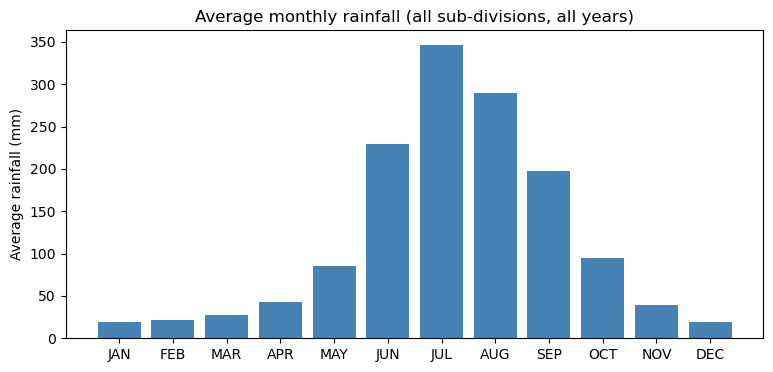

Share of annual rainfall by season (%):
JF       2.9
MAM     11.0
JJAS    75.3
OND     10.9
dtype: float64


In [32]:
month_avg = df[months].mean()

plt.figure(figsize=(9, 4))
plt.bar(month_avg.index, month_avg.values, color="steelblue")
plt.ylabel("Average rainfall (mm)")
plt.title("Average monthly rainfall (all sub-divisions, all years)")
plt.show()

season_share = df[["JF", "MAM", "JJAS", "OND"]].sum() / df["ANNUAL"].sum() * 100
print("Share of annual rainfall by season (%):")
print(season_share.round(1))

### Rainfall in different sub-divisions

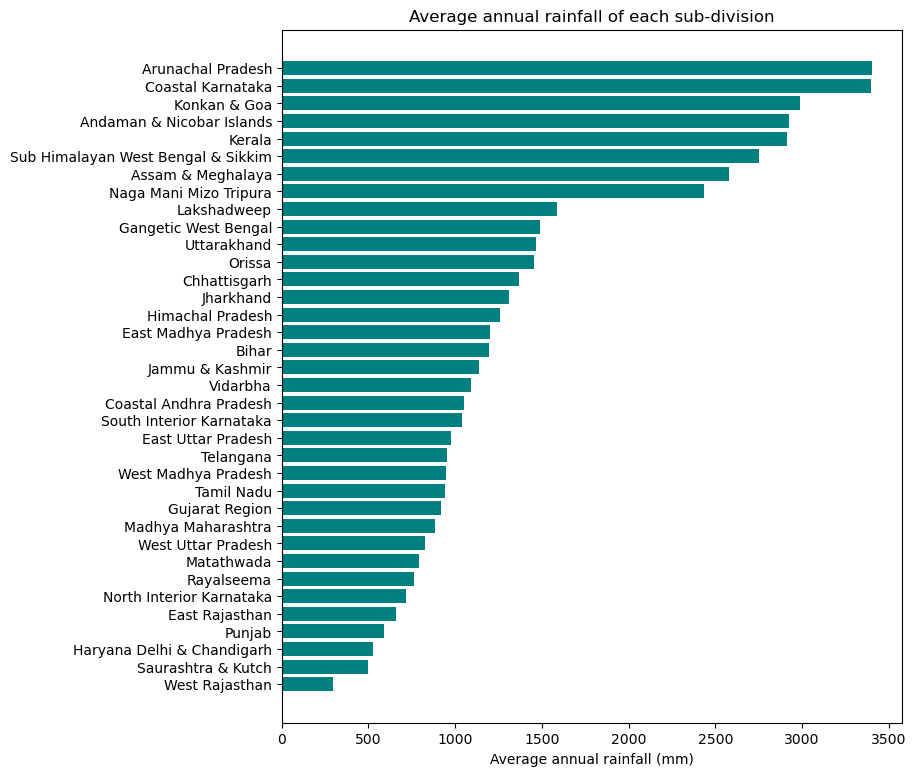

In [41]:
sub_mean = df.groupby("SUBDIVISION")["ANNUAL"].mean().sort_values()

plt.figure(figsize=(8, 9))
plt.barh(sub_mean.index, sub_mean.values, color="teal")
plt.xlabel("Average annual rainfall (mm)")
plt.title("Average annual rainfall of each sub-division")
plt.show()

### Rainfall over the years

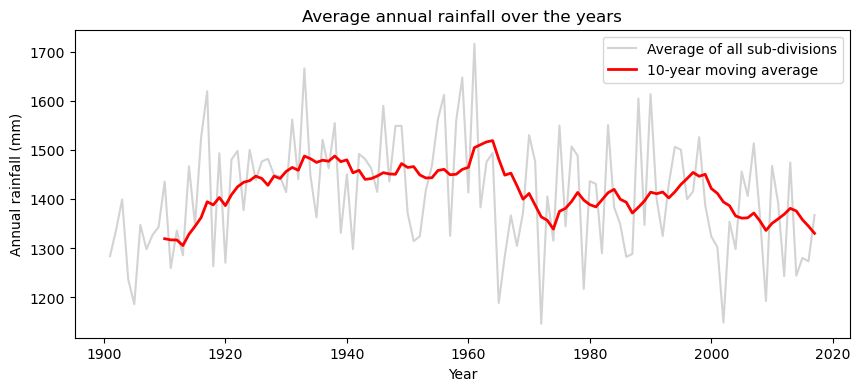

In [9]:
year_avg = df.groupby("YEAR")["ANNUAL"].mean()

plt.figure(figsize=(10, 4))
plt.plot(year_avg.index, year_avg.values, color="lightgray", label="Average of all sub-divisions")
plt.plot(year_avg.index, year_avg.rolling(10).mean(), color="red", linewidth=2, label="10-year moving average")
plt.xlabel("Year")
plt.ylabel("Annual rainfall (mm)")
plt.title("Average annual rainfall over the years")
plt.legend()
plt.show()

## Seasonal Rainfall Trends overt time

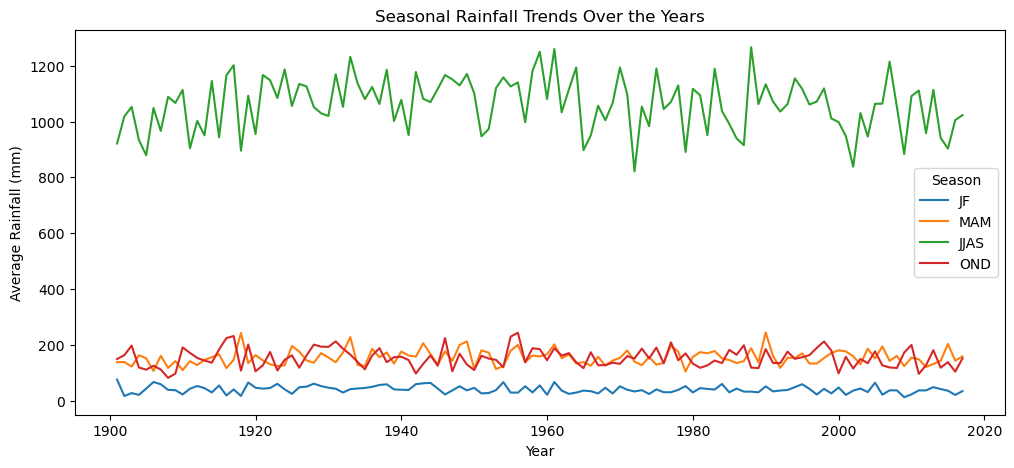

In [37]:
seasons = ["JF", "MAM", "JJAS", "OND"]

season_year = df.groupby("YEAR")[seasons].mean()

season_year.plot(
    figsize=(12, 5),
    linewidth=1.5
)

plt.title("Seasonal Rainfall Trends Over the Years")
plt.xlabel("Year")
plt.ylabel("Average Rainfall (mm)")
plt.legend(title="Season")
plt.show()

## Train and test split

In [10]:
# split by year: old years for training, recent years for testing
train = df[df["YEAR"] <= 2000]
test = df[df["YEAR"] > 2000]
print("Training rows:", len(train), "  Test rows:", len(test))

Training rows: 3552   Test rows: 610


## Regression: Annual Rainfall Estimation Using Monsoon Rainfall

In [27]:
monsoon = ["JUN", "JUL", "AUG", "SEP"]
y_train = train["ANNUAL"]
y_test = test["ANNUAL"]

### Baseline

In [28]:
# baseline: predict each sub-division's average annual rainfall (from the training years)
normal_annual = train.groupby("SUBDIVISION")["ANNUAL"].mean()
pred_base = test["SUBDIVISION"].map(normal_annual)

r2_base = r2_score(y_test, pred_base)
mae_base = mean_absolute_error(y_test, pred_base)
rmse_base = mean_squared_error(y_test, pred_base) ** 0.5
print("Baseline:  R2 = %.3f   MAE = %.0f mm   RMSE = %.0f mm" % (r2_base, mae_base, rmse_base))

Baseline:  R2 = 0.835   MAE = 239 mm   RMSE = 342 mm


### Model 1: Simple Linear Regression (ANNUAL from JJAS)

In [29]:
model1 = LinearRegression()
model1.fit(train[["JJAS"]], y_train)
pred1 = model1.predict(test[["JJAS"]])

r2_1 = r2_score(y_test, pred1)
mae_1 = mean_absolute_error(y_test, pred1)
rmse_1 = mean_squared_error(y_test, pred1) ** 0.5
print("Simple Linear Regression:  R2 = %.3f   MAE = %.0f mm   RMSE = %.0f mm" % (r2_1, mae_1, rmse_1))
print("Equation: ANNUAL = %.1f + %.2f x JJAS" % (model1.intercept_, model1.coef_[0]))

Simple Linear Regression:  R2 = 0.879   MAE = 229 mm   RMSE = 293 mm
Equation: ANNUAL = 126.5 + 1.21 x JJAS


### Model 2: Multiple Linear Regression (ANNUAL from JUN, JUL, AUG, SEP)

In [30]:
model2 = LinearRegression()
model2.fit(train[monsoon], y_train)
pred2 = model2.predict(test[monsoon])

r2_2 = r2_score(y_test, pred2)
mae_2 = mean_absolute_error(y_test, pred2)
rmse_2 = mean_squared_error(y_test, pred2) ** 0.5
print("Multiple Linear Regression:  R2 = %.3f   MAE = %.0f mm   RMSE = %.0f mm" % (r2_2, mae_2, rmse_2))

Multiple Linear Regression:  R2 = 0.900   MAE = 203 mm   RMSE = 266 mm


### Model 3: Polynomial Regression (degree 2)

In [16]:
poly = PolynomialFeatures(degree=2, include_bias=False)
X_train_poly = poly.fit_transform(train[monsoon])
X_test_poly = poly.transform(test[monsoon])

model3 = LinearRegression()
model3.fit(X_train_poly, y_train)
pred3 = model3.predict(X_test_poly)

r2_3 = r2_score(y_test, pred3)
mae_3 = mean_absolute_error(y_test, pred3)
rmse_3 = mean_squared_error(y_test, pred3) ** 0.5
print("Polynomial Regression:  R2 = %.3f   MAE = %.0f mm   RMSE = %.0f mm" % (r2_3, mae_3, rmse_3))

Polynomial Regression:  R2 = 0.907   MAE = 196 mm   RMSE = 257 mm


### Regression comparison

          Model    R2  MAE (mm)  RMSE (mm)
       Baseline 0.835   238.741    341.671
  Simple Linear 0.879   229.250    292.606
Multiple Linear 0.900   202.834    265.825
     Polynomial 0.907   196.425    256.724


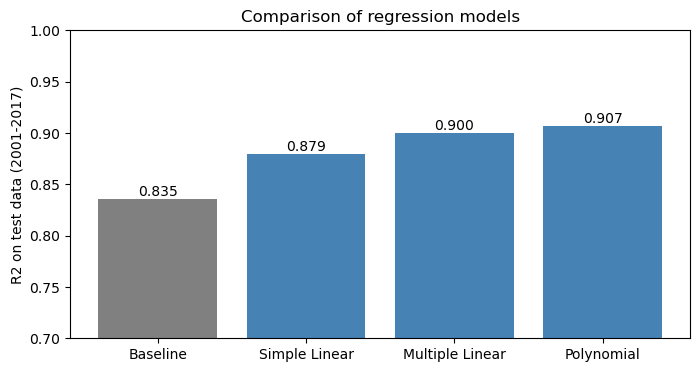

In [17]:
reg_names = ["Baseline", "Simple Linear", "Multiple Linear", "Polynomial"]
reg_r2 = [r2_base, r2_1, r2_2, r2_3]
reg_mae = [mae_base, mae_1, mae_2, mae_3]
reg_rmse = [rmse_base, rmse_1, rmse_2, rmse_3]

reg_table = pd.DataFrame({"Model": reg_names, "R2": reg_r2, "MAE (mm)": reg_mae, "RMSE (mm)": reg_rmse})
print(reg_table.round(3).to_string(index=False))

plt.figure(figsize=(8, 4))
plt.bar(reg_names, reg_r2, color=["gray", "steelblue", "steelblue", "steelblue"])
for i in range(len(reg_r2)):
    plt.text(i, reg_r2[i] + 0.003, "%.3f" % reg_r2[i], ha="center")
plt.ylim(0.7, 1.0)
plt.ylabel("R2 on test data (2001-2017)")
plt.title("Comparison of regression models")
plt.show()

## Classification (deficient-rainfall year)

In [18]:
# deficient year = annual rainfall at least 20% below the sub-division's normal (training average)
y_train_c = (train["ANNUAL"] <= 0.8 * train["SUBDIVISION"].map(normal_annual)).astype(int)
y_test_c = (test["ANNUAL"] <= 0.8 * test["SUBDIVISION"].map(normal_annual)).astype(int)

print("Deficient years in training data: %.1f%%" % (y_train_c.mean() * 100))
print("Deficient years in test data:     %.1f%%" % (y_test_c.mean() * 100))

# baseline: always predict 'normal'
baseline_acc = 1 - y_test_c.mean()
print("Baseline accuracy (always 'normal'): %.3f" % baseline_acc)

Deficient years in training data: 13.9%
Deficient years in test data:     24.4%
Baseline accuracy (always 'normal'): 0.756


### Input features (rainfall up to July, as % of normal)

In [19]:
jan_jul = months[:7]

# normals from the training years only
normal_total = train[jan_jul].sum(axis=1).groupby(train["SUBDIVISION"]).mean()
normal_jun = train.groupby("SUBDIVISION")["JUN"].mean()
normal_jul = train.groupby("SUBDIVISION")["JUL"].mean()

X_train_c = pd.DataFrame()
X_train_c["JanJul_pct"] = train[jan_jul].sum(axis=1) / train["SUBDIVISION"].map(normal_total) * 100
X_train_c["JUN_pct"] = train["JUN"] / train["SUBDIVISION"].map(normal_jun) * 100
X_train_c["JUL_pct"] = train["JUL"] / train["SUBDIVISION"].map(normal_jul) * 100

X_test_c = pd.DataFrame()
X_test_c["JanJul_pct"] = test[jan_jul].sum(axis=1) / test["SUBDIVISION"].map(normal_total) * 100
X_test_c["JUN_pct"] = test["JUN"] / test["SUBDIVISION"].map(normal_jun) * 100
X_test_c["JUL_pct"] = test["JUL"] / test["SUBDIVISION"].map(normal_jul) * 100

X_train_c.describe().round(1)

,JanJul_pct,JUN_pct,JUL_pct
count,3552.0,3552.0,3552.0
mean,100.0,100.0,100.0
std,24.4,48.9,35.4
min,10.2,1.4,0.0
25%,84.7,68.1,77.2
50%,98.7,94.2,97.1
75%,113.9,123.6,120.1
max,225.7,517.8,322.2


### Scaling (for Logistic Regression, KNN and SVM)

In [20]:
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train_c)
X_test_scaled = scaler.transform(X_test_c)

### Model 1: Logistic Regression

In [21]:
lr = LogisticRegression(max_iter=1000)
lr.fit(X_train_scaled, y_train_c)
pred_lr = lr.predict(X_test_scaled)

acc_lr = accuracy_score(y_test_c, pred_lr)
prec_lr = precision_score(y_test_c, pred_lr, zero_division=0)
rec_lr = recall_score(y_test_c, pred_lr)
f1_lr = f1_score(y_test_c, pred_lr)
print("Logistic Regression:  Accuracy = %.3f   Precision = %.3f   Recall = %.3f   F1 = %.3f" % (acc_lr, prec_lr, rec_lr, f1_lr))
print("Confusion matrix (rows = actual, columns = predicted):")
print(confusion_matrix(y_test_c, pred_lr))

Logistic Regression:  Accuracy = 0.818   Precision = 0.771   Recall = 0.362   F1 = 0.493
Confusion matrix (rows = actual, columns = predicted):
[[445  16]
 [ 95  54]]


### Model 2: K-Nearest Neighbours (k = 15)

In [22]:
knn = KNeighborsClassifier(n_neighbors=15)
knn.fit(X_train_scaled, y_train_c)
pred_knn = knn.predict(X_test_scaled)

acc_knn = accuracy_score(y_test_c, pred_knn)
prec_knn = precision_score(y_test_c, pred_knn, zero_division=0)
rec_knn = recall_score(y_test_c, pred_knn)
f1_knn = f1_score(y_test_c, pred_knn)
print("KNN:  Accuracy = %.3f   Precision = %.3f   Recall = %.3f   F1 = %.3f" % (acc_knn, prec_knn, rec_knn, f1_knn))
print("Confusion matrix (rows = actual, columns = predicted):")
print(confusion_matrix(y_test_c, pred_knn))

KNN:  Accuracy = 0.830   Precision = 0.714   Recall = 0.503   F1 = 0.591
Confusion matrix (rows = actual, columns = predicted):
[[431  30]
 [ 74  75]]


### Model 3: Naive Bayes

In [23]:
nb = GaussianNB()
nb.fit(X_train_c, y_train_c)
pred_nb = nb.predict(X_test_c)

acc_nb = accuracy_score(y_test_c, pred_nb)
prec_nb = precision_score(y_test_c, pred_nb, zero_division=0)
rec_nb = recall_score(y_test_c, pred_nb)
f1_nb = f1_score(y_test_c, pred_nb)
print("Naive Bayes:  Accuracy = %.3f   Precision = %.3f   Recall = %.3f   F1 = %.3f" % (acc_nb, prec_nb, rec_nb, f1_nb))
print("Confusion matrix (rows = actual, columns = predicted):")
print(confusion_matrix(y_test_c, pred_nb))

Naive Bayes:  Accuracy = 0.831   Precision = 0.667   Recall = 0.617   F1 = 0.641
Confusion matrix (rows = actual, columns = predicted):
[[415  46]
 [ 57  92]]


### Model 4: Decision Tree (max depth 4)

In [24]:
dt = DecisionTreeClassifier(max_depth=4, random_state=42)
dt.fit(X_train_c, y_train_c)
pred_dt = dt.predict(X_test_c)

acc_dt = accuracy_score(y_test_c, pred_dt)
prec_dt = precision_score(y_test_c, pred_dt, zero_division=0)
rec_dt = recall_score(y_test_c, pred_dt)
f1_dt = f1_score(y_test_c, pred_dt)
print("Decision Tree:  Accuracy = %.3f   Precision = %.3f   Recall = %.3f   F1 = %.3f" % (acc_dt, prec_dt, rec_dt, f1_dt))
print("Confusion matrix (rows = actual, columns = predicted):")
print(confusion_matrix(y_test_c, pred_dt))

Decision Tree:  Accuracy = 0.800   Precision = 0.737   Recall = 0.282   F1 = 0.408
Confusion matrix (rows = actual, columns = predicted):
[[446  15]
 [107  42]]


### Model 5: Support Vector Machine

In [25]:
svm = SVC()
svm.fit(X_train_scaled, y_train_c)
pred_svm = svm.predict(X_test_scaled)

acc_svm = accuracy_score(y_test_c, pred_svm)
prec_svm = precision_score(y_test_c, pred_svm, zero_division=0)
rec_svm = recall_score(y_test_c, pred_svm)
f1_svm = f1_score(y_test_c, pred_svm)
print("SVM:  Accuracy = %.3f   Precision = %.3f   Recall = %.3f   F1 = %.3f" % (acc_svm, prec_svm, rec_svm, f1_svm))
print("Confusion matrix (rows = actual, columns = predicted):")
print(confusion_matrix(y_test_c, pred_svm))

SVM:  Accuracy = 0.815   Precision = 0.781   Recall = 0.336   F1 = 0.469
Confusion matrix (rows = actual, columns = predicted):
[[447  14]
 [ 99  50]]


### Classification comparison

              Model  Accuracy  Precision  Recall  F1 score
Logistic Regression     0.818      0.771   0.362     0.493
                KNN     0.830      0.714   0.503     0.591
        Naive Bayes     0.831      0.667   0.617     0.641
      Decision Tree     0.800      0.737   0.282     0.408
                SVM     0.815      0.781   0.336     0.469


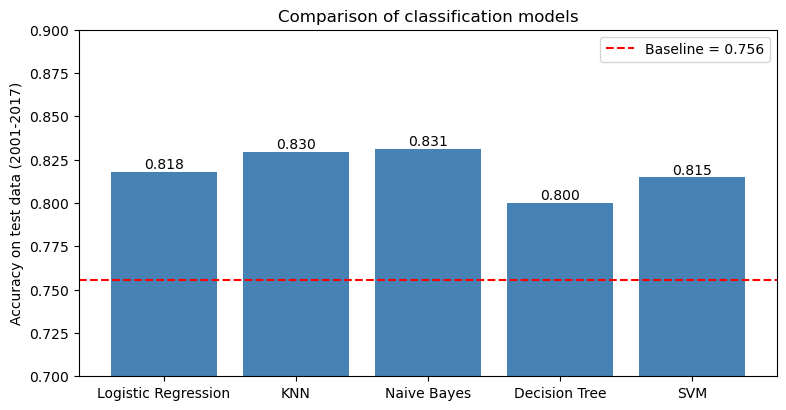

In [26]:
cls_names = ["Logistic Regression", "KNN", "Naive Bayes", "Decision Tree", "SVM"]
cls_acc = [acc_lr, acc_knn, acc_nb, acc_dt, acc_svm]
cls_prec = [prec_lr, prec_knn, prec_nb, prec_dt, prec_svm]
cls_rec = [rec_lr, rec_knn, rec_nb, rec_dt, rec_svm]
cls_f1 = [f1_lr, f1_knn, f1_nb, f1_dt, f1_svm]

cls_table = pd.DataFrame({"Model": cls_names, "Accuracy": cls_acc, "Precision": cls_prec,
                          "Recall": cls_rec, "F1 score": cls_f1})
print(cls_table.round(3).to_string(index=False))

plt.figure(figsize=(9, 4.5))
plt.bar(cls_names, cls_acc, color="steelblue")
plt.axhline(baseline_acc, color="red", linestyle="--", label="Baseline = %.3f" % baseline_acc)
for i in range(len(cls_acc)):
    plt.text(i, cls_acc[i] + 0.002, "%.3f" % cls_acc[i], ha="center")
plt.ylim(0.7, 0.9)
plt.ylabel("Accuracy on test data (2001-2017)")
plt.title("Comparison of classification models")
plt.legend()
plt.show()

## Conclusion
This project explored historical rainfall patterns across India's meteorological subdivisions using EDA and Machine Learning.

EDA: Revealed seasonal variations, regional differences and historical rainfall trends.

Regression: Polynomial Regression performed best, achieving an R² score of 0.907.

Classification: Naive Bayes achieved the best F1 score of 0.641, identifying deficient rainfall years using January–July rainfall patterns.